# GridShift TFT — Notebook 01: Data Audit and Cleaning

This notebook audits and cleans the hourly India grid dataset. It displays tables and charts inline and **does not save cleaned datasets, scalers, reports, or plot images to disk**.

**Input expected:** `January 2024- June 2025.xlsx`, worksheet `Report`, with columns `Timestamp`, `Demand (MW)`, `Solar (MW)`, `Wind (MW)`, and `Total Generation (MW)`.

Place the workbook in `data/raw/` beside this notebook, or change `DATA_FILE` in Cell 1. The notebook reads only the hourly `Report` sheet, not older technical sheets with different sampling intervals.


In [1]:
# 1. Imports and configuration
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("data/raw")
MAIN_FILE_NAME = "January 2024- June 2025.xlsx"
MAIN_SHEET = "Report"
TIMESTAMP_FORMAT = "%d-%m-%Y %H:%M:%S"

# Older monthly workbooks use a different schema and finer sampling intervals.
# These mappings are based on the workbook's metadata/header labels.
LEGACY_SHEET = "Sheet1"
LEGACY_TIME_COL = "Time"
LEGACY_DEMAND_COL = "SCADA/ANALOG/044MQ067/0"  # NLDC_DEMAND|P
LEGACY_WIND_COL = "SCADA/ANALOG/044MQ070/0"    # ALL_INDIA_WIND|P
LEGACY_SOLAR_COL = "Unnamed: 7"                 # derived Solar column (non-negative in sample)
LEGACY_TOTAL_COL = "Unnamed: 9"                # derived Total column

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
print("Working directory:", Path.cwd())
print("Data folder:", DATA_DIR.resolve())
print("Data folder exists:", DATA_DIR.exists())


Working directory: d:\Github Repos\GridShift-TFT
Data folder: D:\Github Repos\GridShift-TFT\data\raw
Data folder exists: True


## 2. Load the workbooks

The notebook expects the main hourly workbook and any older monthly workbooks to be in `data/raw/`. It reads the main `Report` sheet and then checks other `.xlsx` files for the known legacy `Sheet1` structure. Incompatible files are listed as skipped in the source audit table.


## 2. Load multiple workbooks

This version loads the main `Report` sheet plus compatible monthly workbooks in `data/raw/`. The older files use a different schema and finer time intervals, so the notebook maps their demand, wind, solar, and total-generation columns, then aggregates them to hourly means before combining. A source audit table shows which files were loaded or skipped.

The legacy column mapping is based on the workbook labels in the dataset audit. Review the source audit and resulting plots to confirm that the values and time coverage look sensible before modeling. The main hourly report takes priority if timestamps overlap.


In [2]:
# 2. Load and standardize all compatible source workbooks

main_path = DATA_DIR / MAIN_FILE_NAME
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find data folder: {DATA_DIR.resolve()}\\n"
        "Create data/raw/ beside this notebook and put the Excel workbooks there."
    )
if not main_path.exists():
    raise FileNotFoundError(
        f"Could not find the main hourly workbook: {main_path.resolve()}\\n"
        "Check MAIN_FILE_NAME in Cell 1."
    )

# Read the modern hourly report sheet.
main_raw = pd.read_excel(main_path, sheet_name=MAIN_SHEET, header=0)
main_required = ["Timestamp", "Demand (MW)", "Wind (MW)", "Solar (MW)", "Total Generation (MW)"]
missing_main = [c for c in main_required if c not in main_raw.columns]
if missing_main:
    raise ValueError(f"Main Report sheet is missing columns: {missing_main}")

main_df = main_raw[main_required].copy()
main_df["timestamp"] = pd.to_datetime(
    main_df["Timestamp"], format=TIMESTAMP_FORMAT, errors="coerce"
)
for c in ["Demand (MW)", "Solar (MW)", "Wind (MW)", "Total Generation (MW)"]:
    main_df[c] = pd.to_numeric(main_df[c], errors="coerce")
main_df = main_df.rename(columns={
    "Demand (MW)": "load_mw",
    "Solar (MW)": "solar_mw",
    "Wind (MW)": "wind_mw",
    "Total Generation (MW)": "total_generation_mw",
})
main_df = main_df[["timestamp", "load_mw", "solar_mw", "wind_mw", "total_generation_mw"]]
main_df["source_file"] = MAIN_FILE_NAME
main_df["source_type"] = "hourly_report"
main_df["source_priority"] = 0

# Read each other Excel workbook as a legacy monthly workbook when its expected columns exist.
# The legacy files contain finer-than-hourly observations, so aggregate them to hourly means.
legacy_frames = []
source_audit = [{
    "file": MAIN_FILE_NAME,
    "source_type": "hourly_report",
    "sheet": MAIN_SHEET,
    "rows_read": len(main_raw),
    "valid_timestamp_rows": int(main_df["timestamp"].notna().sum()),
    "rows_after_hourly_aggregation": len(main_df),
    "status": "loaded",
}]

excel_paths = sorted(
    p for p in DATA_DIR.glob("*.xlsx")
    if p.name != MAIN_FILE_NAME and not p.name.startswith("~$")
)

for path in excel_paths:
    try:
        old = pd.read_excel(path, sheet_name=LEGACY_SHEET, header=0)
    except Exception as exc:
        source_audit.append({
            "file": path.name, "source_type": "legacy_monthly", "sheet": LEGACY_SHEET,
            "rows_read": 0, "valid_timestamp_rows": 0,
            "rows_after_hourly_aggregation": 0,
            "status": f"skipped: could not read sheet ({type(exc).__name__})",
        })
        continue

    needed = [LEGACY_TIME_COL, LEGACY_DEMAND_COL, LEGACY_WIND_COL, LEGACY_SOLAR_COL, LEGACY_TOTAL_COL]
    missing = [c for c in needed if c not in old.columns]
    if missing:
        source_audit.append({
            "file": path.name, "source_type": "legacy_monthly", "sheet": LEGACY_SHEET,
            "rows_read": len(old), "valid_timestamp_rows": 0,
            "rows_after_hourly_aggregation": 0,
            "status": f"skipped: expected columns not found: {missing}",
        })
        continue

    temp = pd.DataFrame({
        "timestamp": pd.to_datetime(old[LEGACY_TIME_COL], errors="coerce"),
        "load_mw": pd.to_numeric(old[LEGACY_DEMAND_COL], errors="coerce"),
        "wind_mw": pd.to_numeric(old[LEGACY_WIND_COL], errors="coerce"),
        "solar_mw": pd.to_numeric(old[LEGACY_SOLAR_COL], errors="coerce"),
        "total_generation_mw": pd.to_numeric(old[LEGACY_TOTAL_COL], errors="coerce"),
    })
    valid_timestamp_rows = int(temp["timestamp"].notna().sum())
    temp = temp.dropna(subset=["timestamp"]).sort_values("timestamp")

    if temp.empty:
        source_audit.append({
            "file": path.name, "source_type": "legacy_monthly", "sheet": LEGACY_SHEET,
            "rows_read": len(old), "valid_timestamp_rows": 0,
            "rows_after_hourly_aggregation": 0, "status": "skipped: no parseable timestamps",
        })
        continue

    # Floor timestamps to the hour and average observations within each hour.
    temp["timestamp"] = temp["timestamp"].dt.floor("h")
    temp = temp.groupby("timestamp", as_index=False)[
        ["load_mw", "solar_mw", "wind_mw", "total_generation_mw"]
    ].mean()
    temp["source_file"] = path.name
    temp["source_type"] = "legacy_hourly_mean"
    temp["source_priority"] = 1
    legacy_frames.append(temp)

    source_audit.append({
        "file": path.name, "source_type": "legacy_monthly", "sheet": LEGACY_SHEET,
        "rows_read": len(old), "valid_timestamp_rows": valid_timestamp_rows,
        "rows_after_hourly_aggregation": len(temp), "status": "loaded and resampled to hourly means",
    })

# Combine standardized datasets. The main report has priority if timestamps overlap.
all_frames = [main_df] + legacy_frames
combined = pd.concat(all_frames, ignore_index=True)
combined = combined.dropna(subset=["timestamp"])
combined = combined.sort_values(["timestamp", "source_priority"])
combined = combined.drop_duplicates(subset=["timestamp"], keep="first")
combined = combined.sort_values("timestamp").reset_index(drop=True)

# Match the column names expected by later audit/cleaning cells.
raw_df = combined.rename(columns={
    "timestamp": "Timestamp",
    "load_mw": "Demand (MW)",
    "solar_mw": "Solar (MW)",
    "wind_mw": "Wind (MW)",
    "total_generation_mw": "Total Generation (MW)",
})
raw_df = raw_df[[
    "Timestamp", "Demand (MW)", "Wind (MW)", "Solar (MW)", "Total Generation (MW)",
    "source_file", "source_type"
]]

source_audit_df = pd.DataFrame(source_audit)
print(f"Source workbooks discovered: {1 + len(excel_paths)}")
print(f"Workbooks loaded: {(source_audit_df['status'].str.startswith('loaded')).sum()}")
print(f"Combined hourly rows: {len(raw_df):,}")
print("Note: older monthly workbooks were resampled to hourly means before combining.")
display(source_audit_df)
display(raw_df.head(10))
display(raw_df.tail(10))


Source workbooks discovered: 29
Workbooks loaded: 29
Combined hourly rows: 33,432
Note: older monthly workbooks were resampled to hourly means before combining.


,file,source_type,sheet,rows_read,valid_timestamp_rows,rows_after_hourly_aggregation,status
0,January 2024- June 2025.xlsx,hourly_report,Report,12990,12984,12990,loaded
1,April 2022.xlsx,legacy_monthly,Sheet1,8641,8640,720,loaded and resampled to hourly means
2,April 2023.xlsx,legacy_monthly,Sheet1,259201,259200,720,loaded and resampled to hourly means
3,August 2022.xlsx,legacy_monthly,Sheet1,8929,8928,744,loaded and resampled to hourly means
4,August 2023.xlsx,legacy_monthly,Sheet1,267841,267840,744,loaded and resampled to hourly means
5,December 2021.xlsx,legacy_monthly,Sheet1,8929,8928,744,loaded and resampled to hourly means
6,December 2022.xlsx,legacy_monthly,Sheet1,267841,267840,744,loaded and resampled to hourly means
7,December 2023.xlsx,legacy_monthly,Sheet1,267841,267840,744,loaded and resampled to hourly means
8,February 2022.xlsx,legacy_monthly,Sheet1,8065,8064,672,loaded and resampled to hourly means
9,February 2023.xlsx,legacy_monthly,Sheet1,241921,241920,672,loaded and resampled to hourly means


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW),source_file,source_type
0,2021-09-01 00:00:00,160844.389323,7759.304118,0.000000,162291.654439,September 2021.xlsx,legacy_hourly_mean
1,2021-09-01 01:00:00,157730.328125,6956.503215,0.000000,159245.315653,September 2021.xlsx,legacy_hourly_mean
2,2021-09-01 02:00:00,155114.600260,6178.605998,0.000000,156646.137716,September 2021.xlsx,legacy_hourly_mean
3,2021-09-01 03:00:00,152914.929688,5957.205322,0.000000,154531.233785,September 2021.xlsx,legacy_hourly_mean
4,2021-09-01 04:00:00,152820.233073,5677.328695,0.000000,154367.283691,September 2021.xlsx,legacy_hourly_mean
5,2021-09-01 05:00:00,153671.634115,5744.472860,2.325591,155502.127613,September 2021.xlsx,legacy_hourly_mean
6,2021-09-01 06:00:00,156394.330729,5407.073201,524.485086,158176.998575,September 2021.xlsx,legacy_hourly_mean
7,2021-09-01 07:00:00,160798.311198,4876.435872,5033.661865,162371.988363,September 2021.xlsx,legacy_hourly_mean
8,2021-09-01 08:00:00,162743.830729,5363.454549,12019.461182,164044.723897,September 2021.xlsx,legacy_hourly_mean
9,2021-09-01 09:00:00,168370.315104,5580.397461,17883.281901,169427.409017,September 2021.xlsx,legacy_hourly_mean


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW),source_file,source_type
33422,2025-06-24 14:00:00,210465.97,25100.87,44698.83,213258.30,January 2024- June 2025.xlsx,hourly_report
33423,2025-06-24 15:00:00,210731.24,25938.18,37194.84,212882.48,January 2024- June 2025.xlsx,hourly_report
33424,2025-06-24 16:00:00,208206.75,25854.57,26095.50,210242.69,January 2024- June 2025.xlsx,hourly_report
33425,2025-06-24 17:00:00,206808.15,25596.34,14996.41,208067.84,January 2024- June 2025.xlsx,hourly_report
33426,2025-06-24 18:00:00,208886.02,24429.56,4935.21,209621.02,January 2024- June 2025.xlsx,hourly_report
33427,2025-06-24 19:00:00,217525.28,24155.33,561.23,218132.01,January 2024- June 2025.xlsx,hourly_report
33428,2025-06-24 20:00:00,218591.04,22126.62,-0.02,219774.81,January 2024- June 2025.xlsx,hourly_report
33429,2025-06-24 21:00:00,219604.51,21730.31,0.00,220812.17,January 2024- June 2025.xlsx,hourly_report
33430,2025-06-24 22:00:00,219476.73,21207.32,0.00,220616.38,January 2024- June 2025.xlsx,hourly_report
33431,2025-06-24 23:00:00,215341.90,20314.42,0.00,216694.55,January 2024- June 2025.xlsx,hourly_report


## 3. Inspect the raw data
Column names, data types, missing values, and descriptive statistics before cleaning.

In [3]:
# 3. Raw structure and missing-value audit
structure = pd.DataFrame({
    "column": raw_df.columns,
    "data_type": [str(dtype) for dtype in raw_df.dtypes],
    "missing_count": raw_df.isna().sum().values,
    "missing_percent": (raw_df.isna().mean().values * 100).round(3),
    "unique_values": [raw_df[c].nunique(dropna=True) for c in raw_df.columns],
})
display(structure)
display(raw_df.head())
display(raw_df.describe(include="all").T)


,column,data_type,missing_count,missing_percent,unique_values
0,Timestamp,datetime64[ns],0,0.0,33432
1,Demand (MW),float64,0,0.0,33381
2,Wind (MW),float64,0,0.0,33097
3,Solar (MW),float64,0,0.0,31030
4,Total Generation (MW),float64,0,0.0,33145
5,source_file,object,0,0.0,29
6,source_type,object,0,0.0,2


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW),source_file,source_type
0,2021-09-01 00:00:00,160844.389323,7759.304118,0.0,162291.654439,September 2021.xlsx,legacy_hourly_mean
1,2021-09-01 01:00:00,157730.328125,6956.503215,0.0,159245.315653,September 2021.xlsx,legacy_hourly_mean
2,2021-09-01 02:00:00,155114.600260,6178.605998,0.0,156646.137716,September 2021.xlsx,legacy_hourly_mean
3,2021-09-01 03:00:00,152914.929688,5957.205322,0.0,154531.233785,September 2021.xlsx,legacy_hourly_mean
4,2021-09-01 04:00:00,152820.233073,5677.328695,0.0,154367.283691,September 2021.xlsx,legacy_hourly_mean


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Timestamp,33432,NaN,NaN,NaN,2023-07-29 11:30:00,2021-09-01 00:00:00,2022-08-15 05:45:00,2023-07-29 11:30:00,2024-07-11 17:15:00,2025-06-24 23:00:00,NaN
Demand (MW),33432.0,NaN,NaN,NaN,180704.957638,0.0,165189.286686,183031.475499,198025.903613,248688.24,23979.797405
Wind (MW),33432.0,NaN,NaN,NaN,8170.595863,0.0,3891.276436,6716.202687,11386.967379,38700.992839,5450.886116
Solar (MW),33432.0,NaN,NaN,NaN,12269.499218,-69.76,62.143954,1305.41382,24217.79482,64701.19,16267.125101
Total Generation (MW),33432.0,NaN,NaN,NaN,182617.392167,0.0,166880.634753,184895.165437,199948.238909,250748.62,24218.516567
source_file,33432,29,January 2024- June 2025.xlsx,12984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_type,33432,2,legacy_hourly_mean,20448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Validate columns and parse timestamps

Timestamps use day-month-year format, for example `01-01-2024 00:00:00`. Parsing is explicit so day/month values are not accidentally swapped.

In [4]:
# 4. Select required columns and parse types
required_cols = ["Timestamp", "Demand (MW)", "Solar (MW)", "Wind (MW)", "Total Generation (MW)"]
missing_cols = [c for c in required_cols if c not in raw_df.columns]
if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}\nFound: {list(raw_df.columns)}")

df = raw_df[required_cols].copy().rename(columns={
    "Timestamp": "timestamp",
    "Demand (MW)": "load_mw",
    "Solar (MW)": "solar_mw",
    "Wind (MW)": "wind_mw",
    "Total Generation (MW)": "total_generation_mw",
})
df["timestamp_original"] = df["timestamp"]
df["timestamp"] = pd.to_datetime(df["timestamp"], format=TIMESTAMP_FORMAT, errors="coerce")
numeric_cols = ["load_mw", "solar_mw", "wind_mw", "total_generation_mw"]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

bad_timestamps = df[df["timestamp"].isna()].copy()
print("Rows with unparseable timestamps:", len(bad_timestamps))
if len(bad_timestamps):
    display(bad_timestamps.head(20))


Rows with unparseable timestamps: 0


## 5. Duplicate timestamps and interval audit

We report duplicates and intervals first. Large numbers of duplicates or non-hourly intervals should be investigated before forecasting.

In [5]:
# 5. Timestamp and interval checks
valid_time_df = df[df["timestamp"].notna()].copy()
duplicate_timestamp_rows = valid_time_df[
    valid_time_df.duplicated(subset=["timestamp"], keep=False)
].sort_values("timestamp")
print("Rows involved in duplicate timestamps:", len(duplicate_timestamp_rows))
if len(duplicate_timestamp_rows):
    display(duplicate_timestamp_rows.head(30))

valid_time_df = valid_time_df.sort_values("timestamp").reset_index(drop=True)
time_diffs = valid_time_df["timestamp"].diff().dropna()
interval_counts = time_diffs.value_counts().rename_axis("time_interval").reset_index(name="count")
interval_counts["percent"] = (interval_counts["count"] / interval_counts["count"].sum() * 100).round(2)
print("Time range:", valid_time_df["timestamp"].min(), "to", valid_time_df["timestamp"].max())
print("Unique timestamps:", valid_time_df["timestamp"].nunique())
print("Exactly one-hour intervals:", int((time_diffs == pd.Timedelta(hours=1)).sum()))
print("Non-hourly intervals:", int((time_diffs != pd.Timedelta(hours=1)).sum()))
display(interval_counts.head(20))


Rows involved in duplicate timestamps: 0
Time range: 2021-09-01 00:00:00 to 2025-06-24 23:00:00
Unique timestamps: 33432
Exactly one-hour intervals: 33431
Non-hourly intervals: 0


,time_interval,count,percent
0,0 days 01:00:00,33431,100.0


## 6. Data-quality checks
Missing values and negative measurements are flagged for inspection; negative values are not automatically deleted.

In [6]:
# 6. Missingness and negative-value audit
quality = pd.DataFrame({
    "column": ["timestamp"] + numeric_cols,
    "missing_count": [valid_time_df["timestamp"].isna().sum()] +
                     [valid_time_df[c].isna().sum() for c in numeric_cols],
    "missing_percent": [valid_time_df["timestamp"].isna().mean() * 100] +
                       [valid_time_df[c].isna().mean() * 100 for c in numeric_cols],
})
quality["missing_percent"] = quality["missing_percent"].round(3)
display(quality)

negative_summary = pd.DataFrame({
    "column": numeric_cols,
    "negative_count": [(valid_time_df[c] < 0).sum() for c in numeric_cols],
})
display(negative_summary)
print("Rows with any missing numeric value:", int(valid_time_df[numeric_cols].isna().any(axis=1).sum()))


,column,missing_count,missing_percent
0,timestamp,0,0.0
1,load_mw,0,0.0
2,solar_mw,0,0.0
3,wind_mw,0,0.0
4,total_generation_mw,0,0.0


,column,negative_count
0,load_mw,0
1,solar_mw,499
2,wind_mw,0
3,total_generation_mw,0


Rows with any missing numeric value: 0


## 7. Visualize the raw time series
Charts display inline and are not saved as image files.

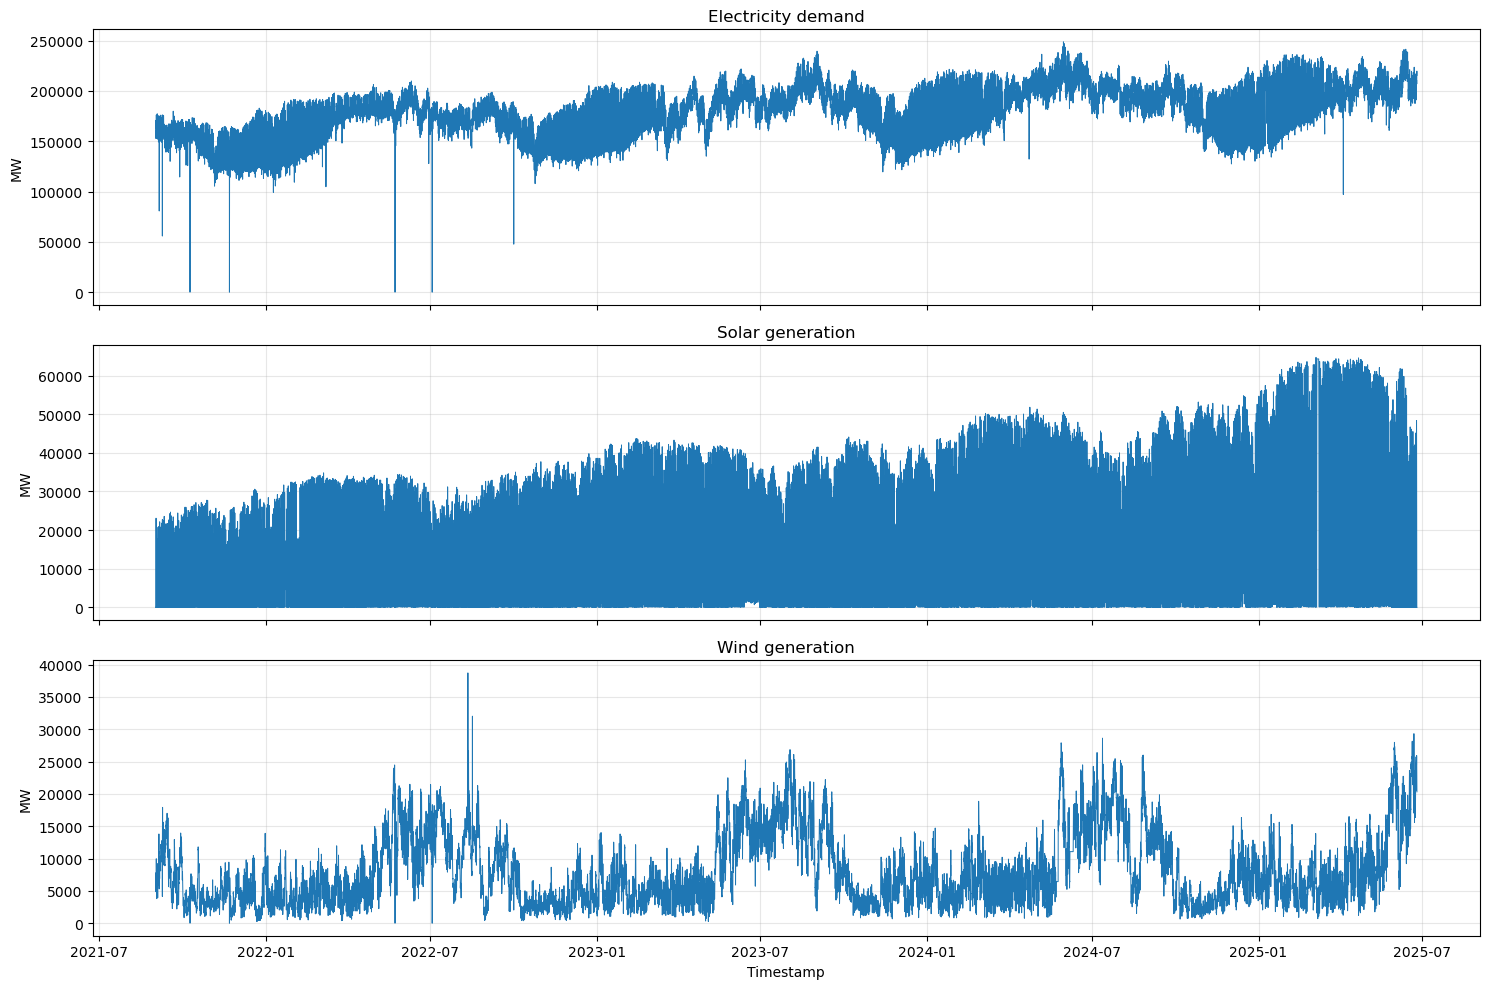

In [7]:
# 7. Raw time-series plots
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for ax, col, title in zip(
    axes, ["load_mw", "solar_mw", "wind_mw"],
    ["Electricity demand", "Solar generation", "Wind generation"]
):
    ax.plot(valid_time_df["timestamp"], valid_time_df[col], linewidth=0.7)
    ax.set_title(title)
    ax.set_ylabel("MW")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()


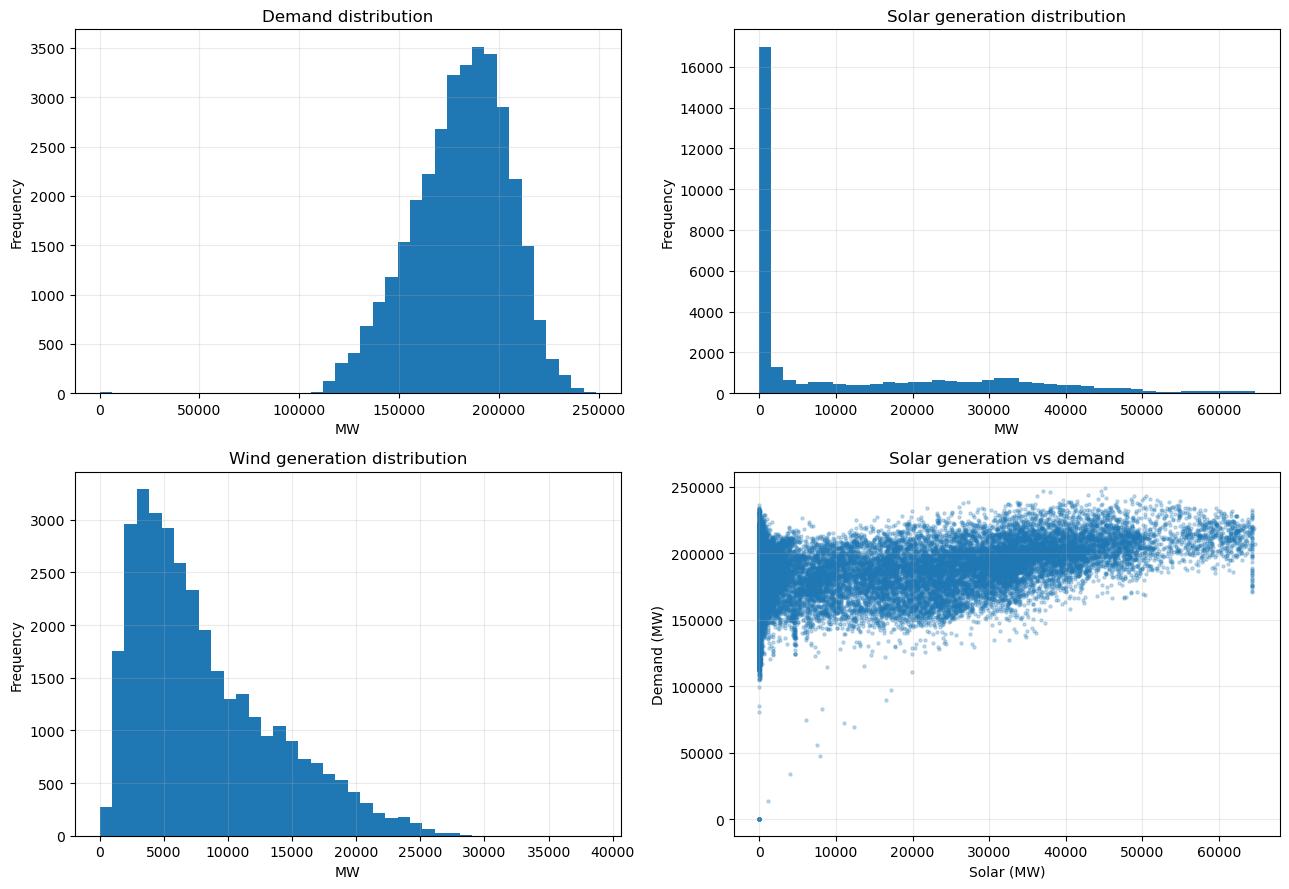

In [8]:
# 8. Distributions and solar-demand relationship
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col, title in [
    (axes[0, 0], "load_mw", "Demand distribution"),
    (axes[0, 1], "solar_mw", "Solar generation distribution"),
    (axes[1, 0], "wind_mw", "Wind generation distribution"),
]:
    ax.hist(valid_time_df[col].dropna(), bins=40)
    ax.set_title(title)
    ax.set_xlabel("MW")
    ax.set_ylabel("Frequency")
    ax.grid(True, alpha=0.25)
axes[1, 1].scatter(valid_time_df["solar_mw"], valid_time_df["load_mw"], s=5, alpha=0.25)
axes[1, 1].set_title("Solar generation vs demand")
axes[1, 1].set_xlabel("Solar (MW)")
axes[1, 1].set_ylabel("Demand (MW)")
axes[1, 1].grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Clean in memory only

Cleaning rules used here:
- Drop rows with unparseable timestamps.
- Sort chronologically.
- Keep the first row for duplicate timestamps and report how many were removed.
- Convert measurement columns to numeric values.
- Interpolate internal gaps of up to three consecutive hourly rows using time interpolation; longer gaps remain missing.
- Do not save any output files.

If the interval audit shows irregular sampling, investigate that before relying on interpolation or modeling.

In [9]:
# 9. Clean data in memory (no disk writes)
rows_before = len(df)
bad_timestamp_count = int(df["timestamp"].isna().sum())
clean_df = df[df["timestamp"].notna()].copy().sort_values("timestamp")
duplicate_rows_removed = int(clean_df.duplicated(subset=["timestamp"], keep="first").sum())
clean_df = clean_df.drop_duplicates(subset=["timestamp"], keep="first")
clean_df = clean_df.set_index("timestamp").sort_index()

missing_before_interpolation = clean_df[numeric_cols].isna().sum()
clean_df[numeric_cols] = clean_df[numeric_cols].interpolate(
    method="time", limit=3, limit_area="inside"
)
missing_after_interpolation = clean_df[numeric_cols].isna().sum()
clean_df = clean_df.reset_index()
clean_df["hour"] = clean_df["timestamp"].dt.hour
clean_df["day_of_week"] = clean_df["timestamp"].dt.dayofweek
clean_df["month"] = clean_df["timestamp"].dt.month
clean_df["day"] = clean_df["timestamp"].dt.day
clean_df["is_weekend"] = clean_df["day_of_week"].isin([5, 6])

print("Cleaned dataframe created in memory only.")
print(f"Rows before: {rows_before:,}")
print(f"Rows removed due to invalid timestamps: {bad_timestamp_count:,}")
print(f"Duplicate timestamp rows removed: {duplicate_rows_removed:,}")


Cleaned dataframe created in memory only.
Rows before: 33,432
Rows removed due to invalid timestamps: 0
Duplicate timestamp rows removed: 0


In [10]:
# 10. Missing values before and after interpolation
missing_comparison = pd.DataFrame({
    "column": numeric_cols,
    "missing_before_interpolation": missing_before_interpolation.values,
    "missing_after_interpolation": missing_after_interpolation.values,
})
display(missing_comparison)
print("Cleaned shape:", clean_df.shape)
display(clean_df.head(10))
display(clean_df.tail(10))


,column,missing_before_interpolation,missing_after_interpolation
0,load_mw,0,0
1,solar_mw,0,0
2,wind_mw,0,0
3,total_generation_mw,0,0


Cleaned shape: (33432, 11)


,timestamp,load_mw,solar_mw,wind_mw,total_generation_mw,timestamp_original,hour,day_of_week,month,day,is_weekend
0,2021-09-01 00:00:00,160844.389323,0.000000,7759.304118,162291.654439,2021-09-01 00:00:00,0,2,9,1,False
1,2021-09-01 01:00:00,157730.328125,0.000000,6956.503215,159245.315653,2021-09-01 01:00:00,1,2,9,1,False
2,2021-09-01 02:00:00,155114.600260,0.000000,6178.605998,156646.137716,2021-09-01 02:00:00,2,2,9,1,False
3,2021-09-01 03:00:00,152914.929688,0.000000,5957.205322,154531.233785,2021-09-01 03:00:00,3,2,9,1,False
4,2021-09-01 04:00:00,152820.233073,0.000000,5677.328695,154367.283691,2021-09-01 04:00:00,4,2,9,1,False
5,2021-09-01 05:00:00,153671.634115,2.325591,5744.472860,155502.127613,2021-09-01 05:00:00,5,2,9,1,False
6,2021-09-01 06:00:00,156394.330729,524.485086,5407.073201,158176.998575,2021-09-01 06:00:00,6,2,9,1,False
7,2021-09-01 07:00:00,160798.311198,5033.661865,4876.435872,162371.988363,2021-09-01 07:00:00,7,2,9,1,False
8,2021-09-01 08:00:00,162743.830729,12019.461182,5363.454549,164044.723897,2021-09-01 08:00:00,8,2,9,1,False
9,2021-09-01 09:00:00,168370.315104,17883.281901,5580.397461,169427.409017,2021-09-01 09:00:00,9,2,9,1,False


,timestamp,load_mw,solar_mw,wind_mw,total_generation_mw,timestamp_original,hour,day_of_week,month,day,is_weekend
33422,2025-06-24 14:00:00,210465.97,44698.83,25100.87,213258.30,2025-06-24 14:00:00,14,1,6,24,False
33423,2025-06-24 15:00:00,210731.24,37194.84,25938.18,212882.48,2025-06-24 15:00:00,15,1,6,24,False
33424,2025-06-24 16:00:00,208206.75,26095.50,25854.57,210242.69,2025-06-24 16:00:00,16,1,6,24,False
33425,2025-06-24 17:00:00,206808.15,14996.41,25596.34,208067.84,2025-06-24 17:00:00,17,1,6,24,False
33426,2025-06-24 18:00:00,208886.02,4935.21,24429.56,209621.02,2025-06-24 18:00:00,18,1,6,24,False
33427,2025-06-24 19:00:00,217525.28,561.23,24155.33,218132.01,2025-06-24 19:00:00,19,1,6,24,False
33428,2025-06-24 20:00:00,218591.04,-0.02,22126.62,219774.81,2025-06-24 20:00:00,20,1,6,24,False
33429,2025-06-24 21:00:00,219604.51,0.00,21730.31,220812.17,2025-06-24 21:00:00,21,1,6,24,False
33430,2025-06-24 22:00:00,219476.73,0.00,21207.32,220616.38,2025-06-24 22:00:00,22,1,6,24,False
33431,2025-06-24 23:00:00,215341.90,0.00,20314.42,216694.55,2025-06-24 23:00:00,23,1,6,24,False


## 9. Visualize cleaned series and typical patterns

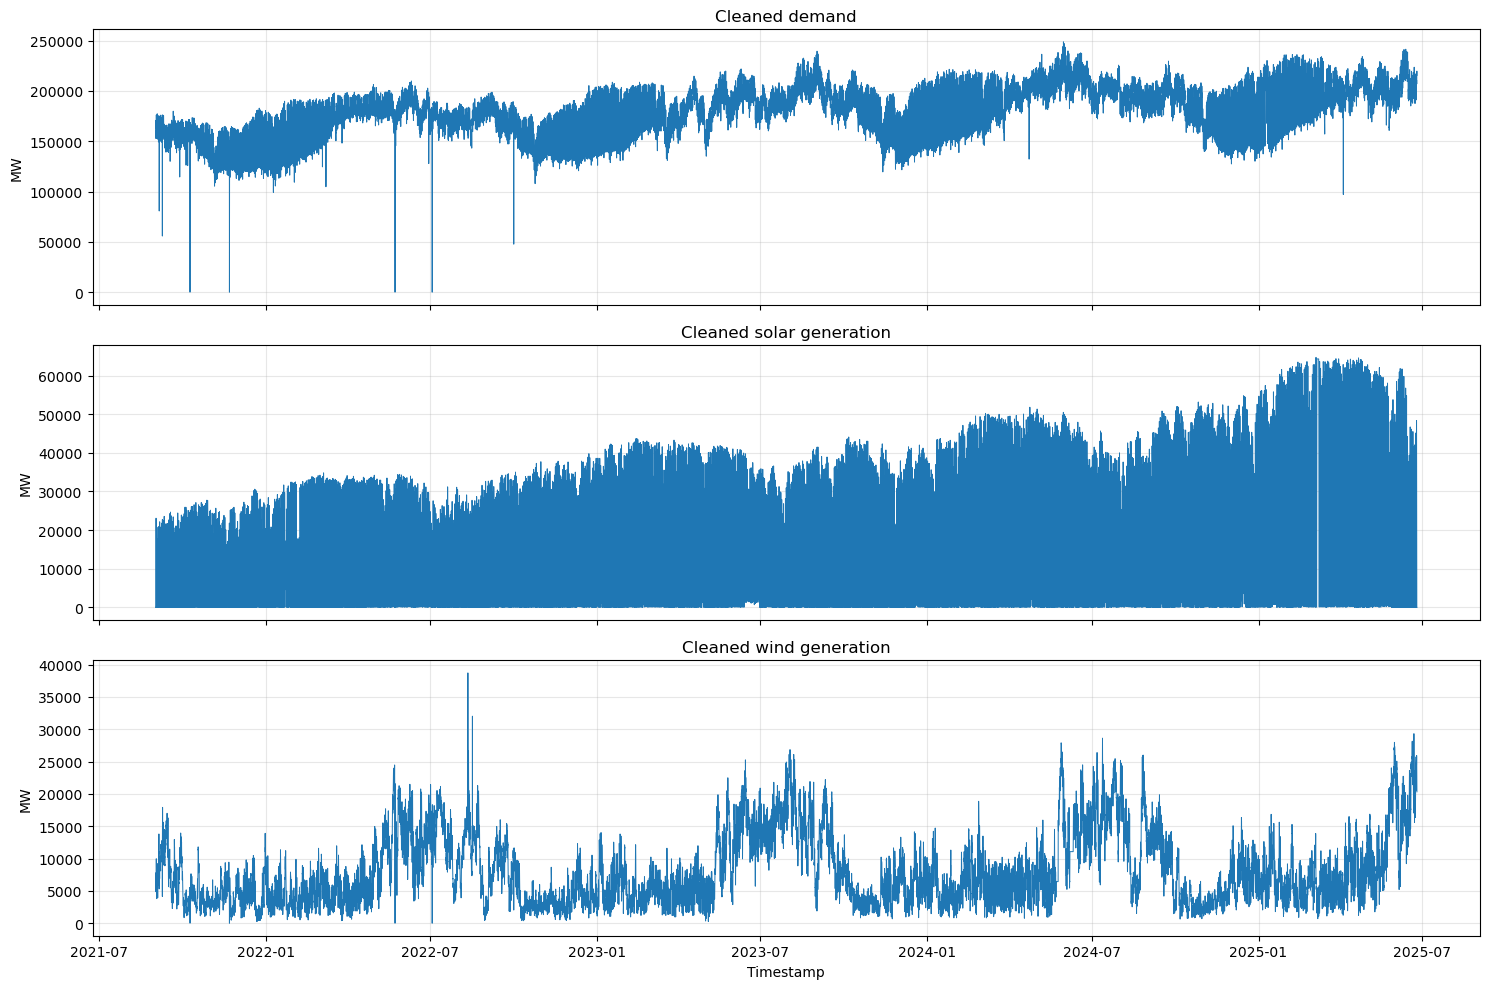

In [11]:
# 11. Cleaned time series
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for ax, col, title in zip(
    axes, ["load_mw", "solar_mw", "wind_mw"],
    ["Cleaned demand", "Cleaned solar generation", "Cleaned wind generation"]
):
    ax.plot(clean_df["timestamp"], clean_df[col], linewidth=0.7)
    ax.set_title(title)
    ax.set_ylabel("MW")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()


Average by hour of day (0 = midnight):


,load_mw,solar_mw,wind_mw
hour,,,
0,169786.91,242.00,9407.70
1,166016.66,237.78,9211.91
2,162816.98,261.05,8967.40
3,161045.57,250.74,8693.23
4,162078.68,249.33,8394.74
5,166982.12,219.75,8056.09
6,174664.28,1089.52,7705.73
7,181672.76,6449.46,7266.20
8,186141.76,17135.58,6949.54


Average by calendar month:


,load_mw,solar_mw,wind_mw
month,,,
1,171733.65,11409.76,5672.14
2,179917.22,13532.49,5319.76
3,183517.18,15218.85,5512.48
4,192757.82,15039.45,6203.60
5,193500.47,14452.40,11047.34
6,199615.41,13499.00,14814.14
7,186972.04,10332.75,15480.21
8,190954.61,10924.36,13192.42
9,181609.79,10664.06,10133.02


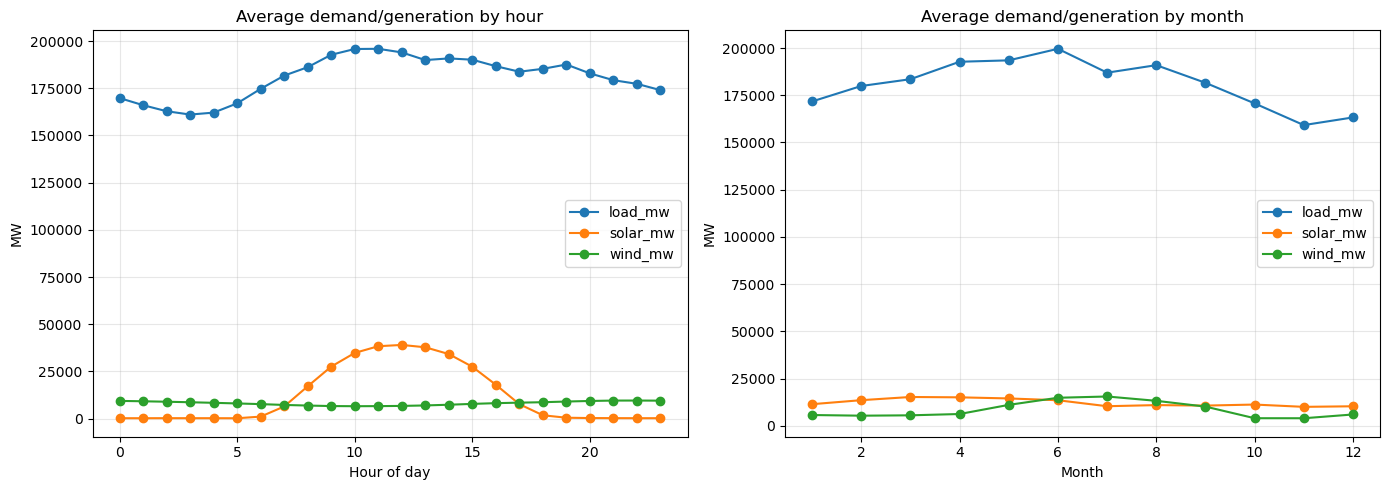

In [12]:
# 12. Average patterns by hour and calendar month
hourly_pattern = clean_df.groupby("hour")[["load_mw", "solar_mw", "wind_mw"]].mean().round(2)
monthly_pattern = clean_df.groupby("month")[["load_mw", "solar_mw", "wind_mw"]].mean().round(2)

print("Average by hour of day (0 = midnight):")
display(hourly_pattern)
print("Average by calendar month:")
display(monthly_pattern)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hourly_pattern.plot(ax=axes[0], marker="o")
axes[0].set_title("Average demand/generation by hour")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MW")
axes[0].grid(True, alpha=0.3)
monthly_pattern.plot(ax=axes[1], marker="o")
axes[1].set_title("Average demand/generation by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("MW")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,load_mw,solar_mw,wind_mw,total_generation_mw
load_mw,1.000,0.462,0.261,0.994
solar_mw,0.462,1.000,-0.147,0.459
wind_mw,0.261,-0.147,1.000,0.269
total_generation_mw,0.994,0.459,0.269,1.000


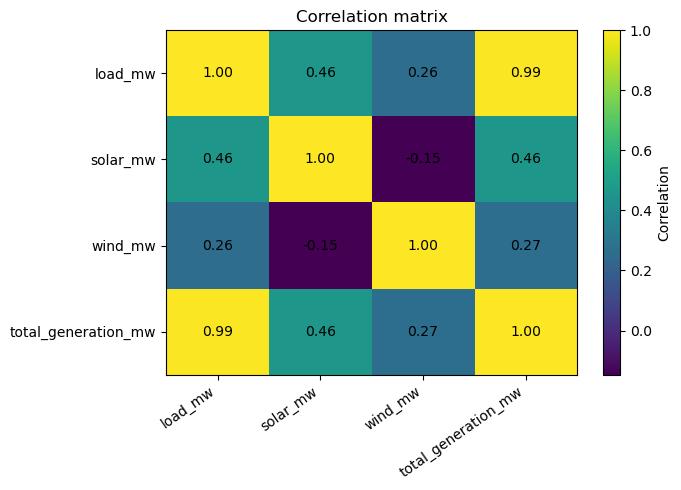

In [13]:
# 13. Correlation table and heatmap
corr = clean_df[numeric_cols].corr(numeric_only=True).round(3)
display(corr)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr.values, aspect="auto")
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr.index)), labels=corr.index)
ax.set_title("Correlation matrix")
fig.colorbar(im, ax=ax, label="Correlation")
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()


## 10. Final audit summary
Review this report before starting forecasting. No CSV, JSON, scaler, or plot files are created.

In [14]:
# 14. Final summary table
nonhourly_after_cleaning = int(
    (clean_df["timestamp"].diff().dropna() != pd.Timedelta(hours=1)).sum()
)
summary = pd.DataFrame([
    ("Input file", str(DATA_FILE)),
    ("Worksheet", SHEET_NAME),
    ("Original rows", rows_before),
    ("Rows with invalid timestamps", bad_timestamp_count),
    ("Duplicate timestamp rows removed", duplicate_rows_removed),
    ("Cleaned rows", len(clean_df)),
    ("Start timestamp", str(clean_df["timestamp"].min())),
    ("End timestamp", str(clean_df["timestamp"].max())),
    ("Non-hourly intervals after cleaning", nonhourly_after_cleaning),
    ("Numeric missing values remaining", int(clean_df[numeric_cols].isna().sum().sum())),
    ("Output saved to disk", "No"),
], columns=["check", "result"])
display(summary)
print("Notebook complete. The cleaned dataframe is available as `clean_df` in memory.")


NameError: name 'DATA_FILE' is not defined